# Monthly Demand Forecasting

## tl;dr
A log-target random forest was selected using May–August 2024 MAE. The following cells rerun the selected implementation and report September–October results separately. Historical accuracy does not establish future performance.

## Context & Methods
Train on earlier months only. Demand and revenue predictors are lagged. The source is an order snapshot, not an independently audited time-series warehouse. Missing covered months after first observation are modeled as zero. No-history materials are outside coverage.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
ROOT = Path.cwd()

import forecast
config = json.loads((ROOT / "model_config.json").read_text())
config

{'name': 'log_random_forest',
 'lags': 12,
 'rolling': True,
 'log_target': True,
 'params': {'n_estimators': 200, 'min_samples_leaf': 3, 'max_depth': 16},
 'selection_months': ['2024-05', '2024-06', '2024-07', '2024-08'],
 'audit_months': ['2024-09', '2024-10'],
 'selection_metric': 'pooled material-month MAE',
 'best_overall_candidate': 'log_random_forest'}

## Data
The original order input is retained losslessly as gzip. This profile reports the cleaned positive-order coverage; the source is not resampled.

In [2]:
panel, profile = forecast.load_panel(ROOT / "data" / "SO.csv.gz")
pd.Series(profile)

source_rows                                                                153679
exact_duplicate_rows_removed                                                    0
usable_rows                                                                153679
materials                                                                     392
first_month                                                               2022-01
last_observed_month                                                       2024-10
zero_month_policy               No observed positive order within a covered mo...
dtype: object

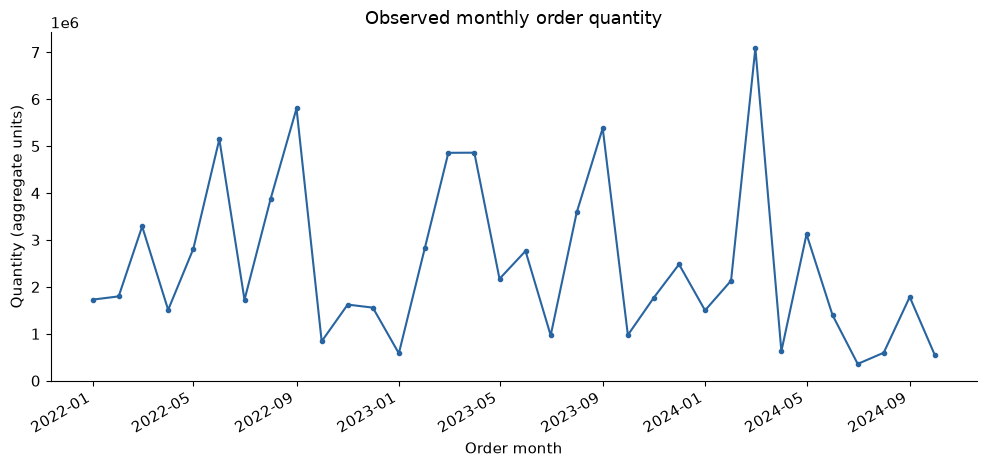

In [3]:
monthly = panel[panel.quantity.notna()].groupby("month").quantity.sum()
fig, ax = plt.subplots()
ax.plot(monthly.index.to_timestamp(), monthly, color="#2864a0", marker="o", markersize=3)
ax.set(title="Observed monthly order quantity", xlabel="Order month", ylabel="Quantity (aggregate units)")
ax.set_ylim(bottom=0)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(ROOT / "results" / "monthly_quantity.png", dpi=150)
plt.show()

## Results
The audit is a rolling one-step evaluation: September truth may be used to train October, but never to predict September itself. The November forecast has no observed ground truth in this input.

In [4]:
summary, audit, future, model = forecast.run()
pd.Series(summary["audit_metrics"])

rows               7.830000e+02
mae                1.684272e+03
rmse               1.136453e+04
wape               5.666366e-01
actual_total       2.327391e+06
predicted_total    1.376445e+06
dtype: float64

In [5]:
comparison = pd.read_csv(ROOT / "results" / "candidate_comparison.csv")
comparison.pivot(index="model", columns="stage", values="mae").sort_values("selection")

stage,audit,selection
model,,
log_random_forest,1684.272006,3275.523958
zero_demand,2972.402299,3539.446960
trailing_three_month_mean,2108.082588,4048.924213
last_month,3230.701149,4185.120310
regularized_random_forest,3091.582873,4364.869306
long_history_random_forest,3013.349239,4814.698550
online_bagged_trees,4852.969716,5081.712898
nearby_random_forest,4066.150067,6349.404257


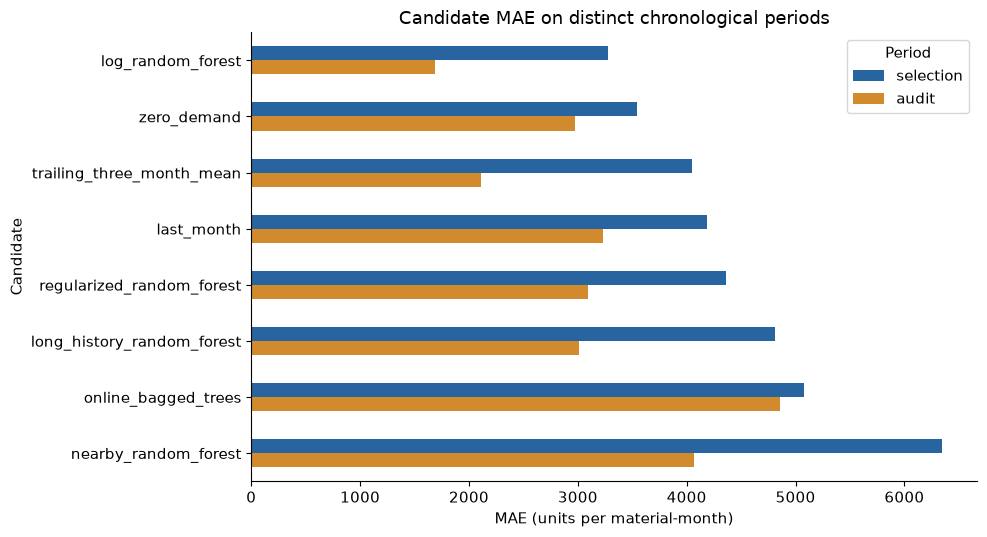

In [6]:
table = comparison.pivot(index="model", columns="stage", values="mae").sort_values("selection")
fig, ax = plt.subplots(figsize=(10, 5.5))
table[["selection", "audit"]].plot.barh(ax=ax, color=["#2864a0", "#d18b2c"])
ax.set(title="Candidate MAE on distinct chronological periods", xlabel="MAE (units per material-month)", ylabel="Candidate")
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.legend(title="Period")
fig.tight_layout()
fig.savefig(ROOT / "results" / "candidate_mae.png", dpi=150)
plt.show()

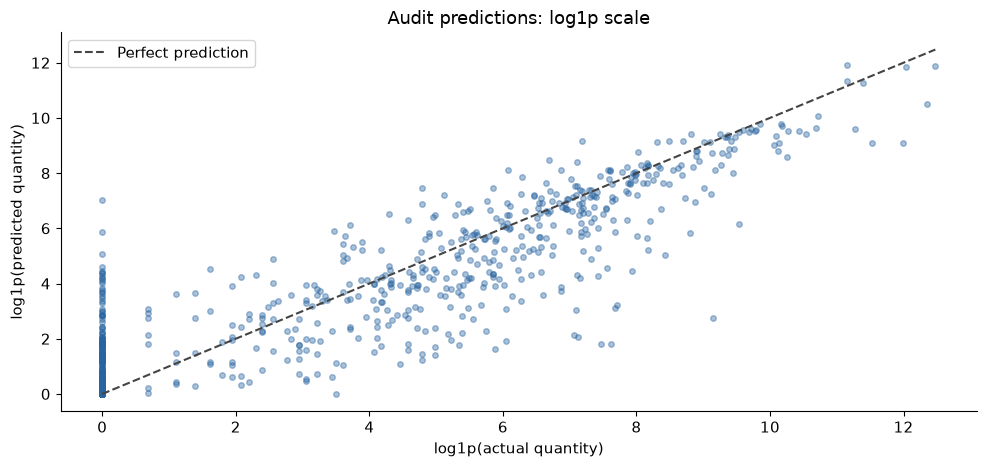

In [7]:
fig, ax = plt.subplots()
ax.scatter(np.log1p(audit.quantity), np.log1p(audit.prediction), alpha=.4, s=16, color="#2864a0")
limit=max(np.log1p(audit.quantity).max(), np.log1p(audit.prediction).max())
ax.plot([0,limit],[0,limit], linestyle="--", color="#444444", label="Perfect prediction")
ax.set(title="Audit predictions: log1p scale", xlabel="log1p(actual quantity)", ylabel="log1p(predicted quantity)")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "results" / "audit_scatter.png", dpi=150)
plt.show()

## Takeaways
The selected model leads validation MAE among the tested candidates and improves on the last-month baseline in the two audit months. Large errors and aggregate underprediction remain. Do not interpret a lower per-material MAE as accurate total demand, a service-level guarantee, or evidence of optimal inventory policy.

In [8]:
totals = audit[["quantity", "prediction"]].sum().rename({"quantity":"Actual", "prediction":"Predicted"})
print("Audit totals:")
print(totals.to_string())
print("Next forecast month:", summary["forecast_month"], "| Materials:", len(future))
future.head(8)

Audit totals:
Actual       2.327391e+06
Predicted    1.376445e+06
Next forecast month: 2024-11 | Materials: 392


,material,month,quantity,prediction,model
27,A3B15_16_MG,2024-11,NaN,7.705753,log_random_forest
62,A3B15_16_WG,2024-11,NaN,520.286750,log_random_forest
97,A3B223DV,2024-11,NaN,121869.723769,log_random_forest
130,A3B31_1A_DG,2024-11,NaN,162.947454,log_random_forest
163,A3B31_3A_DG,2024-11,NaN,0.297249,log_random_forest
197,A3B31_DC,2024-11,NaN,45.398861,log_random_forest
230,A3B31_DG,2024-11,NaN,1.354501,log_random_forest
265,A3B32_1A,2024-11,NaN,62825.592036,log_random_forest
